# 01 - Zipf analysis

This notebook reads collection frequencies from the SQLite vocabulary. It does **not** rescan or retokenize Yelp reviews. Expressive punctuation is excluded from the lexical Zipf view.

The theoretical comparison is $\log(CF_i)=\log(K)+b\log(i)$, where classical Zipf behavior has $b\approx-1$. The main fit uses the high-frequency core (ranks 1–1,000); ranks 1,000–100,000 are reported separately so that a steep rare-term tail is not hidden inside one coefficient. A $\pm0.20$ band around −1 and log-space $R^2\geq0.95$ are explicit descriptive guides, not correctness tests.

In [4]:
import json, os, sqlite3, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_project_root() -> Path:
    if configured_root := os.environ.get('YELPTEXT_PROJECT_ROOT'):
        return Path(configured_root).resolve()
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').is_file() and (candidate / 'src' / 'yelptext').is_dir():
            return candidate
    raise RuntimeError('Cannot locate the project root. Start Jupyter inside this repository.')

ROOT = find_project_root()
os.chdir(ROOT)
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from yelptext.runtime import load_config

CONFIG_PATH = Path(os.environ.get('YELPTEXT_CONFIG', ROOT / 'configs' / 'full.toml')).resolve()
config = load_config(CONFIG_PATH)
vocabulary_path = (ROOT / config['tokenizer']['vocabulary_path']).resolve()
output_dir = ROOT / 'artifacts' / 'zipf'
output_dir.mkdir(parents=True, exist_ok=True)
print(f'Project root: {ROOT}')
print(f'Config:       {CONFIG_PATH}')
print(f'Vocabulary:   {vocabulary_path}')

Project root: F:\1_graduates\text_management\group
Config:       F:\1_graduates\text_management\group\configs\full.toml
Vocabulary:   F:\1_graduates\text_management\group\data\processed\vocabulary-full.sqlite


In [5]:
uri = vocabulary_path.resolve().as_uri() + '?mode=ro'
with sqlite3.connect(uri, uri=True) as connection:
    terms = pd.read_sql_query(
        "SELECT term, cf, df, tags_json FROM terms WHERE term_id <> 0 AND cf > 0 ORDER BY cf DESC, term",
        connection,
    )
lexical = terms[~terms['tags_json'].str.contains('\"punctuation\"', regex=False)].copy()
lexical['rank'] = np.arange(1, len(lexical) + 1)
lexical[['rank', 'term', 'cf', 'df']].head(20)

,rank,term,cf,df
0,1,the,36808193,6305086
1,2,and,26230696,6264562
2,3,i,19105070,4923738
3,4,a,18883450,5444172
4,5,to,17814015,5154789
5,6,was,13457003,4223633
6,7,of,10428194,4186493
8,8,it,8955194,3757878
9,9,for,8691116,4148924
10,10,is,8671328,3973154


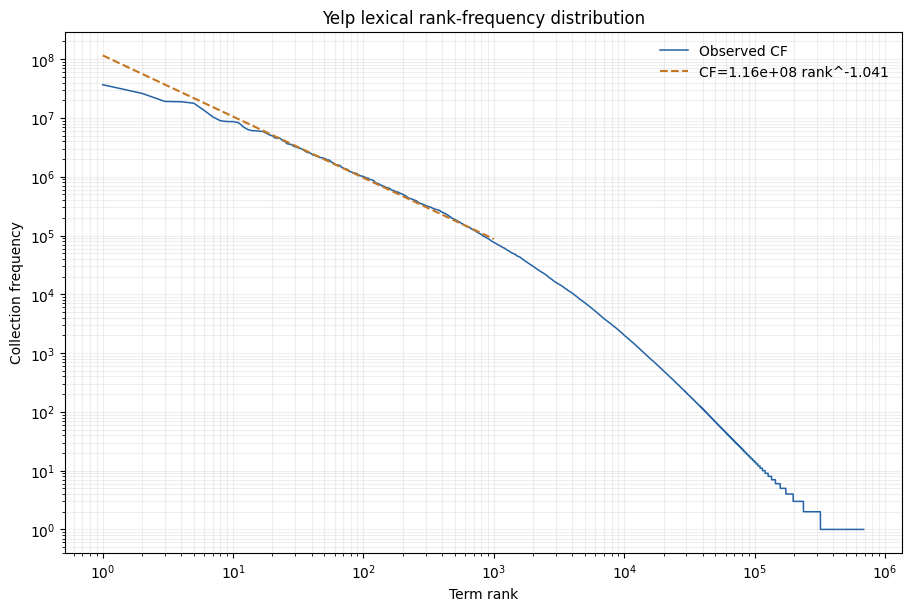

{'config': 'F:\\1_graduates\\text_management\\group\\configs\\full.toml',
 'vocabulary_path': 'F:\\1_graduates\\text_management\\group\\data\\processed\\vocabulary-full.sqlite',
 'observed_lexical_types': 685120,
 'total_lexical_tokens': 734871222,
 'fit_rank_min': 1,
 'fit_rank_max': 1000,
 'slope': -1.0411635474455752,
 'alpha': 1.0411635474455752,
 'K': 116130761.78813152,
 'observed_rank_1_cf': 36808193,
 'r_squared_log_space': 0.9927813634438776,
 'slope_within_0.20_of_minus_one': True,
 'tail_rank_min': 1000,
 'tail_rank_max': 100000,
 'tail_slope': -2.0610466044027165,
 'method': 'OLS on ln(CF) vs ln(rank); descriptive, not a power-law goodness-of-fit test'}

In [6]:
# Estimate the classical Zipf exponent on the high-frequency lexical core.
# The much steeper rare-term tail is measured separately rather than mixed into this fit.
fit_min = 1
fit_max = min(1_000, len(lexical))
fit = lexical[(lexical['rank'] >= fit_min) & (lexical['rank'] <= fit_max)]
slope, intercept = np.polyfit(np.log(fit['rank']), np.log(fit['cf']), 1)
alpha = float(-slope)
K = float(np.exp(intercept))
fitted_log_cf = slope * np.log(fit['rank']) + intercept
ss_res = float(np.sum((np.log(fit['cf']) - fitted_log_cf) ** 2))
ss_tot = float(np.sum((np.log(fit['cf']) - np.log(fit['cf']).mean()) ** 2))
r_squared = 1.0 - ss_res / ss_tot
slope_near_theory = abs(float(slope) + 1.0) <= 0.20
observed_rank_1_cf = int(lexical.iloc[0]['cf'])
tail_min = min(1_000, len(lexical))
tail_max = min(100_000, len(lexical))
tail = lexical[(lexical['rank'] >= tail_min) & (lexical['rank'] <= tail_max)]
tail_slope = float(np.polyfit(np.log(tail['rank']), np.log(tail['cf']), 1)[0]) if len(tail) >= 2 else None

fig, ax = plt.subplots(figsize=(9, 6), layout='constrained')
ax.loglog(lexical['rank'], lexical['cf'], color='#2463A5', linewidth=1.1, label='Observed CF')
fit_rank = np.geomspace(fit_min, fit_max, 300)
ax.loglog(fit_rank, K * fit_rank ** slope, '--', color='#C37722', label=f'CF={K:.3g} rank^{slope:.3f}')
ax.set(xlabel='Term rank', ylabel='Collection frequency', title='Yelp lexical rank-frequency distribution')
ax.grid(alpha=.2, which='both')
ax.legend(frameon=False)
fig.savefig(output_dir / 'zipf_loglog.png', dpi=220)
plt.show()

summary = {
    'config': str(CONFIG_PATH),
    'vocabulary_path': str(vocabulary_path),
    'observed_lexical_types': int(len(lexical)),
    'total_lexical_tokens': int(lexical['cf'].sum()),
    'fit_rank_min': fit_min,
    'fit_rank_max': fit_max,
    'slope': float(slope),
    'alpha': alpha,
    'K': K,
    'observed_rank_1_cf': observed_rank_1_cf,
    'r_squared_log_space': r_squared,
    'slope_within_0.20_of_minus_one': slope_near_theory,
    'tail_rank_min': tail_min,
    'tail_rank_max': tail_max,
    'tail_slope': tail_slope,
    'method': 'OLS on ln(CF) vs ln(rank); descriptive, not a power-law goodness-of-fit test',
}
(output_dir / 'zipf_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
summary

INTERPRETATION

The fitted relation is $\log(CF_i) = \log(K) + b\log(i)$, with
$b=-1.041$, $K=1.16e+08$, and $R^2=0.9928$ in log space
over the high-frequency core, ranks 1–1,000. Equivalently,
$CF_i=1.16e+08i^{-1.041}$.

The classical Zipf expectation is $b\approx-1$. Under the explicit
$\pm0.20$ descriptive tolerance used here, the fitted slope
**is close to −1**. The log–log
relationship is **approximately linear**
by the $R^2\geq0.95$ descriptive criterion. However, the rank
1,000–100,000 tail has slope -2.061, so the complete
distribution is not one perfect Zipf line: rare terms decay more steeply.
$K$ is the regression intercept's rank-one value; the actually observed
rank-one CF is 36,808,193. Reporting both avoids treating the
fitted constant as an observed count.
